# Beavers and post-fire recovery: does vegetation come back faster where beavers are recorded?

Uses the same tables as `stats_cells.ipynb` (`panel.parquet`, `cells.parquet`, `animals/<animal>.parquet`); no new preprocessing.

**Idea.** For every grid cell that burned (first big fire in the record), follow its **August NDVI** year by year after the fire
and measure how much of the fire's NDVI drop has come back. Compare cells with and without beaver records.

| Question | Section | Main number |
|---|---|---|
| Which fires / cells are used? | 2 | cohort table + map |
| What does a typical recovery look like, with vs without beavers? | 3 | recovery curves |
| Do beaver cells reach 90 % recovery **sooner**? | 4 | Kaplan–Meier, log-rank p, Cox hazard ratio (> 1 = faster) |
| Is the whole recovery curve steeper? | 5 | `years × beaver_present` coefficient (> 0 = faster) |
| Same within regions / surveyed areas? | 4–5 | region-stratified Cox, surveyed-only |
| Same at 10, 25, 50 km? | 6 | table |

**Read before interpreting.** Fairfax & Whittle (2020) found greenness rebounded within a year *regardless* of beavers at the
riparian scale, so "no difference" is a plausible and reportable result. Beaver records are observations (more in the
south, near people) and southern vegetation regrows faster anyway, so regional controls matter here too.

In [9]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import statsmodels.formula.api as smf
from statsmodels.duration.survfunc import SurvfuncRight, survdiff

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## Settings

In [10]:
DATA = Path("analysis_data")
GRID = "10km"                     # main grid (25 km: enough burned cells, NDVI not too diluted)
GRIDS = ["10km", "25km", "50km"]  # section 6
ANIMAL = "beaver"

NDVI_MONTH = 8                    # August NDVI each year (same month -> seasonal cycle cancels)
FIRE_YEARS = range(2017, 2024)    # fire years used (need 2 clean years before; 2015 is the first year of data)
MIN_BURN = 0.10                   # a cell's "fire" = at least 10 % of its land burned in one season
CLEAN = 0.005                     # "no fire" = less than 0.5 % burned
REBURN = 0.05                     # a later season with >= 5 % burned ends the cell's recovery series
MIN_DROP = 0.01                   # ignore cells whose NDVI barely dropped (nothing to recover from)
RECOVERED_AT = 0.9                # "recovered" = 90 % of the NDVI drop has come back
MAX_YEARS = 9                     # follow cells up to 9 years after the fire

MIN_LAND = 0.3
MIN_VALID = 0.5
LAT_BAND = 2                      # never-burned cells in the same latitude band give the "normal" year-to-year change
BLOCK_KM = 500                    # region size for region-stratified models
SURVEY_KM = 100                   # "surveyed" = a beaver record within this distance
BOOTSTRAP = 300                   # resamples for confidence bands (regions are resampled, not cells)

## 1. Build a recovery series for every burned cell

For each cell:
1. **Fire year `Y`**: first season (in `FIRE_YEARS`) with ≥ 10 % burned, and no fire (≥ 0.5 %) in *any* earlier season of the record.
2. **Baseline**: mean August NDVI of the two years before `Y`.
3. **Year 0**: the first August after the fire (`Y` if most of the burning was before August, otherwise `Y + 1`).
4. **Climate-adjusted anomaly** each year: (NDVI − baseline) minus the median of the same quantity for **never-burned cells
   at the same latitude**. A dry or wet summer moves everyone; this removes it.
5. **Drop** = −anomaly in year 0. **Recovery ratio** = 1 + anomaly / drop: **0 = no recovery, 1 = back to baseline**.
   The ratio also cancels the dilution of partly burned cells (a 15 % and a 60 % burned cell are comparable).
6. The series stops at a **reburn** (≥ 5 % burned again) or after `MAX_YEARS`.

In [11]:
def surveyed_flag(cells, meta, present):
    km = meta["cell_size_m"] / 1000
    grid = np.zeros((meta["height"], meta["width"]), bool)
    grid[cells["row"], cells["col"]] = present
    r = int(np.ceil(SURVEY_KM / km))
    return ndi.maximum_filter(grid, size=2 * r + 1)[cells["row"], cells["col"]].astype(int)


def build_recovery(grid):
    d = DATA / grid
    meta = json.loads((d / "meta.json").read_text())
    cells = pd.read_parquet(d / "cells.parquet")
    cells = cells[cells["land_frac"] >= MIN_LAND].reset_index(drop=True)
    animal = pd.read_parquet(d / "animals" / f"{ANIMAL}.parquet")[["cell_id", "n"]]
    cells = cells.merge(animal.rename(columns={"n": "beaver_n"}), on="cell_id", how="left")
    cells["beaver_n"] = cells["beaver_n"].fillna(0).astype(int)
    cells["beaver_present"] = (cells["beaver_n"] > 0).astype(int)
    cells["surveyed"] = surveyed_flag(cells, meta, cells["beaver_present"].values > 0)
    km = meta["cell_size_m"] / 1000
    cells["block"] = ((cells["row"] * km) // BLOCK_KM).astype(int) * 10000 + ((cells["col"] * km) // BLOCK_KM).astype(int)

    ndvi_months = [m for m in meta["ndvi_months"] if int(m[5:]) == NDVI_MONTH]
    p = pd.read_parquet(d / "panel.parquet", columns=["cell_id", "month", "ndvi_mean", "ndvi_valid_frac", "burned_frac"],
                        filters=[("month", "in", ndvi_months + meta["burn_months"])])
    p["year"] = p["month"].str[:4].astype(int)
    p["mon"] = p["month"].str[5:].astype(int)

    years_n = sorted({int(m[:4]) for m in ndvi_months})
    years_b = sorted({int(m[:4]) for m in meta["burn_months"]})
    ids = cells["cell_id"].values

    aug = p[p["mon"] == NDVI_MONTH]
    A = aug.pivot(index="cell_id", columns="year", values="ndvi_mean").reindex(index=ids, columns=years_n)
    V = aug.pivot(index="cell_id", columns="year", values="ndvi_valid_frac").reindex(index=ids, columns=years_n)
    A = A.where(V >= MIN_VALID)
    b = p[p["month"].isin(meta["burn_months"])]
    S = b.groupby(["cell_id", "year"])["burned_frac"].sum().unstack().reindex(index=ids, columns=years_b).fillna(0)
    E = (b[b["mon"] < NDVI_MONTH].groupby(["cell_id", "year"])["burned_frac"].sum().unstack()
         .reindex(index=ids, columns=years_b).fillna(0))

    band = ((cells["lat"] // LAT_BAND) * LAT_BAND).values
    never = (S < CLEAN).all(axis=1).values                      # reference cells: never burned in the record
    burned_before = np.zeros(len(ids), bool)
    assigned = np.zeros(len(ids), bool)
    rows = []
    for Y in years_b:
        if Y in FIRE_YEARS and (Y - 1) in years_n and (Y - 2) in years_n:
            pick = (S[Y].values >= MIN_BURN) & ~burned_before & ~assigned
            base = A[[Y - 2, Y - 1]].mean(axis=1, skipna=False).values
            pick &= ~np.isnan(base)
            if pick.any():
                t0 = np.where(E[Y].values >= 0.5 * S[Y].values, Y, Y + 1)
                later = [y for y in years_b if y > Y]
                reb = np.full(len(ids), 9999)
                for y in reversed(later):
                    reb = np.where(S[y].values >= REBURN, y, reb)
                for yr in [y for y in years_n if Y <= y <= Y + 1 + MAX_YEARS]:
                    ref = pd.Series(A[yr].values - base)[never].groupby(band[never]).median()
                    anom = (A[yr].values - base) - pd.Series(band).map(ref).values
                    ok = pick & (yr >= t0) & (yr - t0 <= MAX_YEARS) & (yr < reb) & ~np.isnan(anom)
                    for i in np.flatnonzero(ok):
                        rows.append((ids[i], Y, yr, yr - t0[i], anom[i], base[i], S[Y].values[i]))
                assigned |= pick
        burned_before |= S[Y].values >= CLEAN

    L = pd.DataFrame(rows, columns=["cell_id", "fire_year", "year", "k", "anom", "ndvi_base", "burned_frac"])
    drop = L[L["k"] == 0].set_index("cell_id")["anom"].mul(-1).rename("drop")
    L = L.merge(drop, on="cell_id")
    L = L[L["drop"] >= MIN_DROP]
    L["rr"] = 1 + L["anom"] / L["drop"]
    L = L.merge(cells[["cell_id", "lat", "lon", "beaver_n", "beaver_present", "surveyed", "block"]], on="cell_id")
    return L, cells


def per_cell(L):
    """One row per cohort cell: time until RECOVERED_AT (event) or last year observed (censored)."""
    def summarise(g):
        g = g.sort_values("k")
        hit = g[(g["k"] >= 1) & (g["rr"] >= RECOVERED_AT)]
        return pd.Series({"time": hit["k"].iloc[0] if len(hit) else g["k"].max(), "event": int(len(hit) > 0),
                          "last_k": g["k"].max()})
    out = L.groupby("cell_id").apply(summarise, include_groups=False).reset_index()
    first = L[L["k"] == 0].drop(columns=["year", "k", "anom", "rr"])
    out = out.merge(first, on="cell_id")
    out = out[out["last_k"] >= 1]                                  # need at least one post-fire year
    for c in ("drop", "burned_frac", "ndvi_base", "lat", "lon"):
        out[c + "_z"] = (out[c] - out[c].mean()) / out[c].std()
    return out


L, cells_all = build_recovery(GRID)
cc = per_cell(L)
print(f"{GRID}: {cc['cell_id'].nunique():,} burned cells followed | with {ANIMAL} records {cc['beaver_present'].sum():,} | "
      f"recovered to {RECOVERED_AT:.0%}: {cc['event'].sum():,} | still recovering (censored): {(1 - cc['event']).sum():,}")

10km: 5,825 burned cells followed | with beaver records 162 | recovered to 90%: 2,279 | still recovering (censored): 3,546


## 2. Which fires are used

,cells,with_records,median_drop,median_burned,years_followed
fire_year,,,,,
2017,820,21,0.066,0.345,8.0
2018,688,23,0.066,0.316,7.0
2019,453,8,0.079,0.294,7.0
2020,436,28,0.075,0.351,5.0
2021,872,38,0.070,0.350,5.0
2022,467,16,0.073,0.253,4.0
2023,2089,28,0.096,0.408,3.0


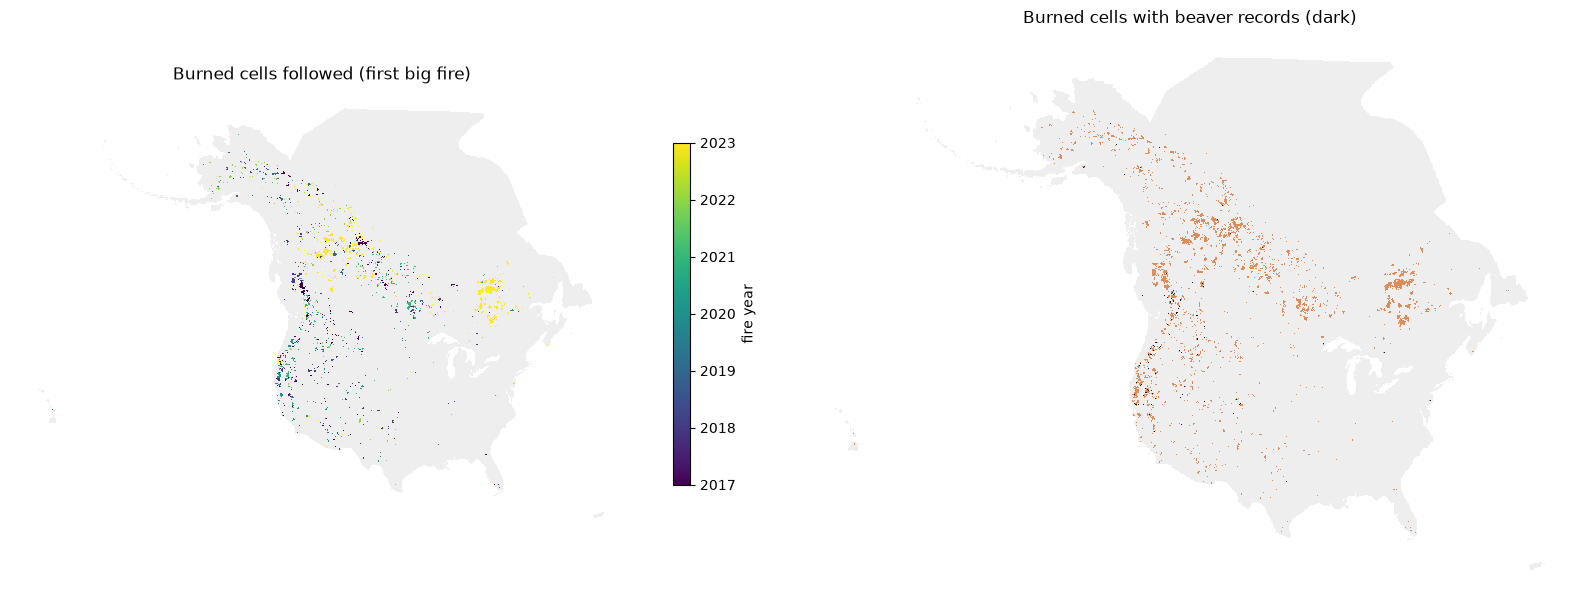

In [12]:
display(cc.groupby("fire_year").agg(cells=("cell_id", "size"), with_records=("beaver_present", "sum"),
                                    median_drop=("drop", "median"), median_burned=("burned_frac", "median"),
                                    years_followed=("last_k", "median")).round(3))

grid_geo = gpd.read_file(DATA / GRID / "grid.gpkg")[["cell_id", "geometry"]]
allc = grid_geo.merge(cells_all[["cell_id"]], on="cell_id")
g = grid_geo.merge(cc, on="cell_id")
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
allc.plot(ax=ax[0], color="#eeeeee")
g.plot(ax=ax[0], column="fire_year", cmap="viridis", legend=True, legend_kwds={"shrink": 0.6, "label": "fire year"})
ax[0].set_title("Burned cells followed (first big fire)")
allc.plot(ax=ax[1], color="#eeeeee")
g.plot(ax=ax[1], column="beaver_present", cmap="copper_r", vmin=-0.5, vmax=1.2)
ax[1].set_title(f"Burned cells with {ANIMAL} records (dark)")
for a in ax:
    a.set_axis_off()
plt.tight_layout()
plt.show()

## 3. Recovery curves

Median recovery ratio by years since the fire, for burned cells with and without beaver records.
Bands = 95 % bootstrap interval, resampling whole **regions** (neighbouring cells are not independent).

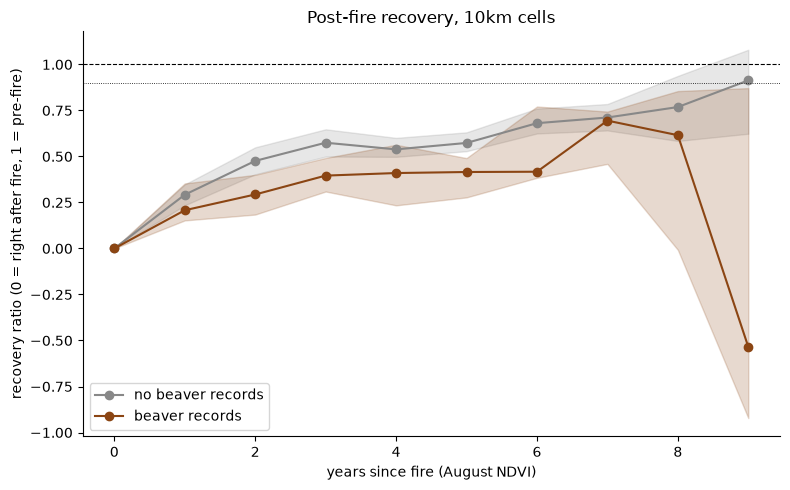

cells observed at each year:


k,0,1,2,3,4,5,6,7,8,9
beaver_present,,,,,,,,,,
0,5663,5663,5547,4899,3188,2548,1739,1573,938,291
1,162,162,156,141,118,91,49,42,32,5


In [13]:
def curve(L, rng=None):
    data = L
    if rng is not None:                                    # resample regions with replacement
        blocks = L["block"].unique()
        pick = rng.choice(blocks, len(blocks), replace=True)
        data = pd.concat([L[L["block"] == b] for b in pick])
    return data.groupby(["beaver_present", "k"])["rr"].median().unstack(0)


Lc = L[L["cell_id"].isin(cc["cell_id"])]
med = curve(Lc)
rng = np.random.default_rng(0)
boots = [curve(Lc, rng) for _ in range(BOOTSTRAP)]
lo = pd.concat(boots).groupby(level=0).quantile(0.025)
hi = pd.concat(boots).groupby(level=0).quantile(0.975)
n_at = Lc.groupby(["k", "beaver_present"]).size().unstack()

fig, ax = plt.subplots(figsize=(8, 5))
for present, color, label in ((0, "#888888", f"no {ANIMAL} records"), (1, "#8b4513", f"{ANIMAL} records")):
    if present in med:
        ax.plot(med.index, med[present], "o-", color=color, label=label)
        ax.fill_between(med.index, lo[present], hi[present], color=color, alpha=0.2)
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.axhline(RECOVERED_AT, color="black", lw=0.6, ls=":")
ax.set_xlabel("years since fire (August NDVI)")
ax.set_ylabel("recovery ratio (0 = right after fire, 1 = pre-fire)")
ax.set_title(f"Post-fire recovery, {GRID} cells")
ax.legend()
plt.tight_layout()
plt.show()
print("cells observed at each year:")
display(n_at.T)

## 4. Time to recovery (survival analysis)

"Event" = the first year a cell reaches 90 % recovery. Cells that have not recovered by the end of the data are
**censored** (counted as "not yet", not as "never"). Kaplan–Meier curves show the share of cells *not yet recovered*.

- **Log-rank test**: are the two curves different?
- **Cox model**: hazard ratio of `beaver_present` — **> 1 = recovers faster**, < 1 = slower — adjusted for fire size,
  NDVI drop, pre-fire NDVI and location. Also **stratified by region** (each region has its own baseline) and **surveyed cells only**.

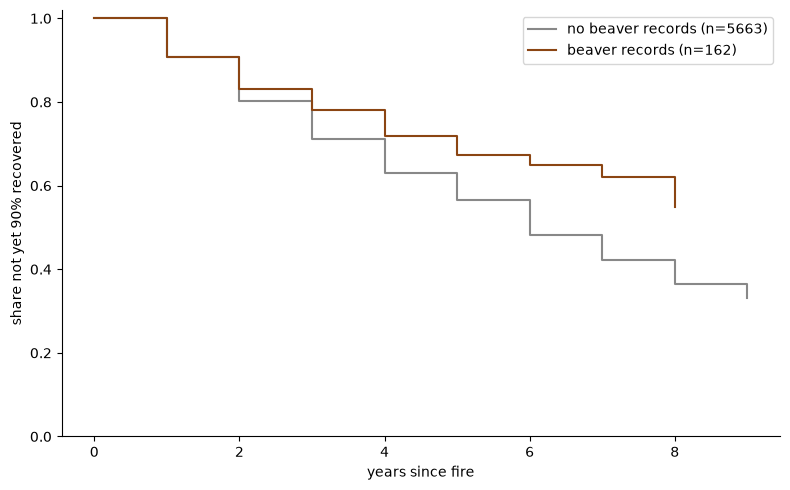

log-rank test: chi2 = 7.22, p = 0.0072


,hazard_ratio,ci_low,ci_high,p,cells,recovered
"all cells, lat/lon controls",0.629,0.473,0.836,0.001,5825.0,2279.0
within region (stratified),0.774,0.574,1.045,0.094,5825.0,2279.0
surveyed cells only,0.637,0.478,0.847,0.002,4529.0,1726.0
surveyed + within region,0.767,0.568,1.035,0.083,4529.0,1726.0


In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
for present, color, label in ((0, "#888888", f"no {ANIMAL} records"), (1, "#8b4513", f"{ANIMAL} records")):
    s = cc[cc["beaver_present"] == present]
    if len(s):
        sf = SurvfuncRight(s["time"], s["event"])
        ax.step(np.r_[0, sf.surv_times], np.r_[1, sf.surv_prob], where="post", color=color, label=f"{label} (n={len(s)})")
ax.set_xlabel("years since fire")
ax.set_ylabel(f"share not yet {RECOVERED_AT:.0%} recovered")
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

stat, p_lr = survdiff(cc["time"], cc["event"], cc["beaver_present"])
print(f"log-rank test: chi2 = {stat:.2f}, p = {p_lr:.3g}")

COX = "time ~ beaver_present + drop_z + burned_frac_z + ndvi_base_z + lat_z + lon_z"


def cox_hr(data, strata=None):
    if data["event"].sum() < 10 or data["beaver_present"].nunique() < 2:
        return None
    kw = {"strata": data[strata].values} if strata else {}
    res = smf.phreg(COX if not strata else COX.replace(" + lat_z + lon_z", ""), data, status=data["event"].values,
                    ties="efron", **kw).fit()
    i = list(res.model.exog_names).index("beaver_present")
    b, se = res.params[i], res.bse[i]
    return {"hazard_ratio": np.exp(b), "ci_low": np.exp(b - 1.96 * se), "ci_high": np.exp(b + 1.96 * se),
            "p": res.pvalues[i], "cells": len(data), "recovered": int(data["event"].sum())}


def cox_checks(cc):
    rows = {"all cells, lat/lon controls": cox_hr(cc),
            "within region (stratified)": cox_hr(cc, strata="block"),
            "surveyed cells only": cox_hr(cc[cc["surveyed"] == 1]),
            "surveyed + within region": cox_hr(cc[cc["surveyed"] == 1], strata="block")}
    return pd.DataFrame({k: v for k, v in rows.items() if v is not None}).T


cox_table = cox_checks(cc)
cox_table.round(3)

## 5. Is the whole recovery curve steeper?

Regression on every cell-year after the fire: `recovery ratio ~ years × beaver_present + controls`.
The **interaction** `k:beaver_present` = extra recovery per year in beaver cells (> 0 = faster).
Standard errors are clustered by region. A second version adds one intercept per region.

In [15]:
def slope_model(L, region=False):
    data = L[L["k"] >= 1].copy()
    if data["beaver_present"].nunique() < 2 or data["cell_id"].nunique() < 20:
        return None
    f = "rr ~ k * beaver_present + drop + burned_frac + ndvi_base + " + ("C(block)" if region else "lat + lon")
    return smf.ols(f, data=data).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(data["block"])[0]})


rows = {}
for name, region in (("lat/lon controls", False), ("within region", True)):
    m = slope_model(Lc, region)
    if m is not None:
        ci = m.conf_int().loc["k:beaver_present"]
        rows[name] = {"extra_recovery_per_year": m.params["k:beaver_present"], "ci_low": ci[0], "ci_high": ci[1],
                      "p": m.pvalues["k:beaver_present"], "recovery_per_year_no_records": m.params["k"],
                      "cell_years": int(m.nobs)}
slope_table = pd.DataFrame(rows).T
slope_table.round(4)

,extra_recovery_per_year,ci_low,ci_high,p,recovery_per_year_no_records,cell_years
lat/lon controls,-0.0471,-0.0984,0.0041,0.0713,0.064,27182.0
within region,-0.0552,-0.1026,-0.0079,0.0223,0.065,27182.0


## 6. Same analysis at 10, 25 and 50 km

In [16]:
summary = {}
for gname in GRIDS:
    Lg, _ = build_recovery(gname)
    cg = per_cell(Lg)
    Lg = Lg[Lg["cell_id"].isin(cg["cell_id"])]
    row = {"cells": len(cg), "with_records": int(cg["beaver_present"].sum()), "recovered": int(cg["event"].sum())}
    for present in (0, 1):
        s = cg[cg["beaver_present"] == present]
        if len(s):
            row[f"median_years_{'with' if present else 'without'}"] = SurvfuncRight(s["time"], s["event"]).quantile(0.5)
    if cg["beaver_present"].nunique() == 2:
        row["logrank_p"] = survdiff(cg["time"], cg["event"], cg["beaver_present"])[1]
    ct = cox_checks(cg)
    for name, short in (("all cells, lat/lon controls", "HR"), ("within region (stratified)", "HR_region"),
                        ("surveyed + within region", "HR_strict")):
        if name in ct.index:
            row[short], row[short + "_p"] = ct.loc[name, "hazard_ratio"], ct.loc[name, "p"]
    m = slope_model(Lg, region=True)
    if m is not None:
        row["extra_per_year_region"], row["extra_per_year_p"] = m.params["k:beaver_present"], m.pvalues["k:beaver_present"]
    summary[gname] = row
pd.DataFrame(summary).T.round(4)

,cells,with_records,recovered,median_years_without,median_years_with,logrank_p,HR,HR_p,HR_region,HR_region_p,HR_strict,HR_strict_p,extra_per_year_region,extra_per_year_p
10km,5825.0,162.0,2279.0,6.0,NaN,0.0072,0.6286,0.0014,0.7745,0.0943,0.7670,0.0832,-0.0552,0.0223
25km,776.0,77.0,313.0,6.0,NaN,0.1961,0.6542,0.0450,0.9191,0.7439,0.9073,0.7095,0.0004,0.9870
50km,136.0,34.0,56.0,5.0,7.0,0.3606,0.6041,0.1648,0.6520,0.3888,0.6446,0.4077,0.0357,0.3470


## 7. Writing it up

- **Main chart:** the recovery curves (section 3) and the Kaplan–Meier chart (section 4).
- **Main numbers:** Cox hazard ratio **within region** (> 1 = faster recovery) and the **extra recovery per year** (section 5),
  with 95 % CIs, at 10, 25 and 50 km.
- Wording: *"Burned cells with beaver records recovered X % of their NDVI loss per year faster / at a similar rate …"*.
  A null result agrees with Fairfax & Whittle (2020), who saw greenness rebound within a year regardless of beavers.
- Limitations: cell-level NDVI mixes burned and unburned land (the recovery ratio reduces but does not remove this),
  recent fires have only a few years of follow-up (handled as censored), beaver records are observations, not populations.